In [ ]:
import zipfile
import os

zip_path = "/content/Groundnut_Leaf_dataset.zip"
extract_path = "/content/Groundnut_Leaf_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

file_path = "/content/Groundnut_Leaf_dataset.zip"

print("Exists:", os.path.exists(file_path))
print("Size:", os.path.getsize(file_path), "bytes")


Exists: True
Size: 117033315 bytes


In [ ]:
!file "/content/Groundnut_Leaf_dataset.zip"

/content/Groundnut_Leaf_dataset.zip: Zip archive data, at least v2.0 to extract, compression method=store


In [ ]:
import zipfile

file_path = "/content/Groundnut_Leaf_dataset.zip"

print("Valid ZIP:", zipfile.is_zipfile(file_path))

Valid ZIP: True


In [ ]:
import os

print(os.listdir("/content/Groundnut_Leaf_dataset"))

['Groundnut_Leaf_dataset']


In [ ]:
dataset_path = "/content/Groundnut_Leaf_dataset/Groundnut_Leaf_dataset"

print(os.listdir(dataset_path))

['test', 'train']


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'Groundnut_Leaf_dataset.zip', 'Groundnut_Leaf_dataset', 'sample_data']


In [ ]:
import os

root_path = "/content/Groundnut_Leaf_dataset"

train_path = None
test_path = None

for root, dirs, files in os.walk(root_path):
    if "train" in dirs and "test" in dirs:
        train_path = os.path.join(root, "train")
        test_path = os.path.join(root, "test")
        break

print("Train path:", train_path)
print("Test path :", test_path)

Train path: /content/Groundnut_Leaf_dataset/Groundnut_Leaf_dataset/train
Test path : /content/Groundnut_Leaf_dataset/Groundnut_Leaf_dataset/test


In [ ]:
print("Train folders:")
print(os.listdir(train_path))

print("\nTest folders:")
print(os.listdir(test_path))

Train folders:
['early_rust_1', 'late_leaf_spot_1', 'nutrition_deficiency_1', 'healthy_leaf_1', 'rust_1', 'early_leaf_spot_1']

Test folders:
['early_rust_1', 'late_leaf_spot_1', 'nutrition_deficiency_1', 'healthy_leaf_1', 'rust_1', 'early_leaf_spot_1']


In [ ]:
# Required 5 target classes

class_names = [
    "Early Leaf Spot",
    "Late Leaf Spot",
    "Rust",
    "Nutrition Deficiency",
    "Healthy"
]

class_to_idx = {
    "Early Leaf Spot": 0,
    "Late Leaf Spot": 1,
    "Rust": 2,
    "Nutrition Deficiency": 3,
    "Healthy": 4
}

# Map the 6 dataset folders into the required 5 classes
folder_to_class = {
    "early_leaf_spot_1": "Early Leaf Spot",
    "late_leaf_spot_1": "Late Leaf Spot",
    "early_rust_1": "Rust",
    "rust_1": "Rust",
    "nutrition_deficiency_1": "Nutrition Deficiency",
    "healthy_leaf_1": "Healthy"
}

print("Target classes:")
for i, name in enumerate(class_names):
    print(i, "->", name)

Target classes:
0 -> Early Leaf Spot
1 -> Late Leaf Spot
2 -> Rust
3 -> Nutrition Deficiency
4 -> Healthy


In [ ]:
import pandas as pd
import os

def create_dataframe(root_path):
    records = []

    for folder, class_name in folder_to_class.items():

        folder_path = os.path.join(root_path, folder)

        if not os.path.exists(folder_path):
            print("Missing folder:", folder_path)
            continue

        for filename in os.listdir(folder_path):

            if filename.lower().endswith((".jpg", ".jpeg", ".png")):

                records.append({
                    "filepath": os.path.join(folder_path, filename),
                    "class_name": class_name,
                    "label": class_to_idx[class_name]
                })

    return pd.DataFrame(records)


train_df = create_dataframe(train_path)
test_df = create_dataframe(test_path)

print("Training images:", len(train_df))
print("Testing images :", len(test_df))

print("\nTraining class distribution:")
print(train_df["class_name"].value_counts())

print("\nTesting class distribution:")
print(test_df["class_name"].value_counts())

Training images: 7910
Testing images : 2451

Training class distribution:
class_name
Rust                    2380
Late Leaf Spot          1491
Healthy                 1462
Early Leaf Spot         1322
Nutrition Deficiency    1255
Name: count, dtype: int64

Testing class distribution:
class_name
Rust                    818
Nutrition Deficiency    410
Early Leaf Spot         409
Healthy                 409
Late Leaf Spot          405
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Final dataset sizes:")
print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Testing    :", len(test_df))

print("\nTraining distribution:")
print(train_df["class_name"].value_counts())

print("\nValidation distribution:")
print(val_df["class_name"].value_counts())

print("\nTesting distribution:")
print(test_df["class_name"].value_counts())

Final dataset sizes:
Training   : 6328
Validation : 1582
Testing    : 2451

Training distribution:
class_name
Rust                    1904
Late Leaf Spot          1193
Healthy                 1170
Early Leaf Spot         1057
Nutrition Deficiency    1004
Name: count, dtype: int64

Validation distribution:
class_name
Rust                    476
Late Leaf Spot          298
Healthy                 292
Early Leaf Spot         265
Nutrition Deficiency    251
Name: count, dtype: int64

Testing distribution:
class_name
Rust                    818
Nutrition Deficiency    410
Early Leaf Spot         409
Healthy                 409
Late Leaf Spot          405
Name: count, dtype: int64


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms created successfully")

Transforms created successfully


In [ ]:
from torch.utils.data import Dataset
from PIL import Image

class GroundnutDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(row["filepath"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_dataset = GroundnutDataset(
    train_df,
    transform=train_transform
)

val_dataset = GroundnutDataset(
    val_df,
    transform=eval_transform
)

test_dataset = GroundnutDataset(
    test_df,
    transform=eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 6328
Validation: 1582
Test: 2451


In [ ]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully
Training batches: 198
Validation batches: 50
Testing batches: 77


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2, 3, 4])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

print("CLASS WEIGHTS")
print("-----------------------------")

for class_name, weight in zip(class_names, weights):
    print(f"{class_name:25s}: {weight:.4f}")

CLASS WEIGHTS
-----------------------------
Early Leaf Spot          : 1.1974
Late Leaf Spot           : 1.0609
Rust                     : 0.6647
Nutrition Deficiency     : 1.2606
Healthy                  : 1.0817


In [ ]:
import torch.nn as nn
from torchvision import models
from torchvision.models import EfficientNet_B0_Weights

pretrained_weights = EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(
    weights=pretrained_weights
)

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    5
)

model = model.to(device)

print("EfficientNet-B0 loaded successfully")
print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 63.8MB/s]

EfficientNet-B0 loaded successfully
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Loss function and optimizer ready")

Loss function and optimizer ready


In [ ]:
def train_one_epoch(model, loader):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

def evaluate(model, loader):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    avg_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        all_labels,
        all_predictions
    )

train them moddal


In [ ]:
num_epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_f1": []
}

best_f1 = 0.0

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc, val_f1, _, _ = evaluate(
        model,
        val_loader
    )

    scheduler.step(val_f1)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 45)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            "/content/best_groundnut_model.pth"
        )

        print("✓ Best model saved")

print("\nTraining completed.")
print(f"Best Validation Macro F1: {best_f1:.4f}")


Epoch 1/10
---------------------------------------------
Train Loss: 0.4674 | Train Accuracy: 0.8766
Val Loss: 0.1024 | Val Accuracy: 0.9665 | Macro F1: 0.9622
✓ Best model saved

Epoch 2/10
---------------------------------------------
Train Loss: 0.1070 | Train Accuracy: 0.9678
Val Loss: 0.0337 | Val Accuracy: 0.9930 | Macro F1: 0.9921
✓ Best model saved

Epoch 3/10
---------------------------------------------
Train Loss: 0.0624 | Train Accuracy: 0.9831
Val Loss: 0.0376 | Val Accuracy: 0.9886 | Macro F1: 0.9869

Epoch 4/10
---------------------------------------------
Train Loss: 0.0472 | Train Accuracy: 0.9856
Val Loss: 0.0153 | Val Accuracy: 0.9975 | Macro F1: 0.9971
✓ Best model saved

Epoch 5/10
---------------------------------------------
Train Loss: 0.0342 | Train Accuracy: 0.9902
Val Loss: 0.0206 | Val Accuracy: 0.9949 | Macro F1: 0.9942

Epoch 6/10
---------------------------------------------
Train Loss: 0.0354 | Train Accuracy: 0.9902
Val Loss: 0.0189 | Val Accuracy: 0.9

Plot the training results

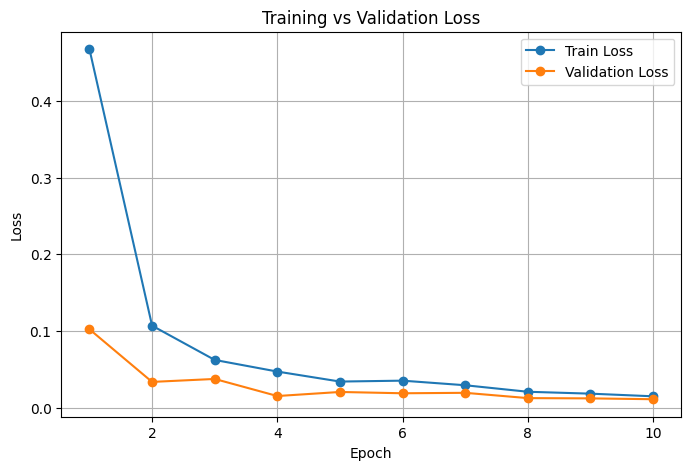

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()

plt.show()

Accuracy:

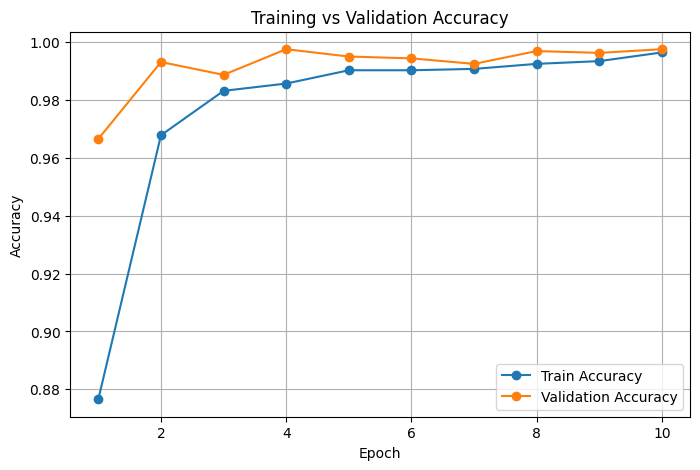

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

Macro F1:

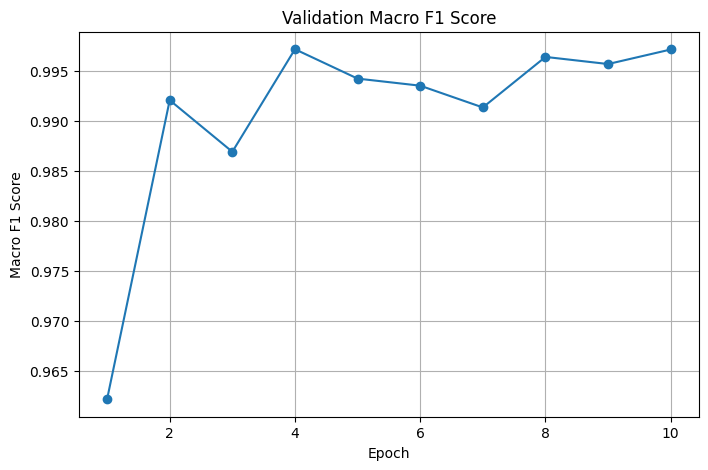

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["val_f1"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1 Score")
plt.title("Validation Macro F1 Score")
plt.grid()

plt.show()

Final test evaluation

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/best_groundnut_model.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded")

Best model loaded


In [ ]:
from sklearn.metrics import balanced_accuracy_score

test_loss, test_accuracy, test_macro_f1, y_true, y_pred = evaluate(
    model,
    test_loader
)

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred
)

print("\nFINAL TEST RESULTS")
print("=" * 40)

print(f"Test Loss         : {test_loss:.4f}")
print(f"Accuracy          : {test_accuracy:.4f}")
print(f"Balanced Accuracy : {balanced_acc:.4f}")
print(f"Macro F1 Score    : {test_macro_f1:.4f}")


FINAL TEST RESULTS
Test Loss         : 0.0562
Accuracy          : 0.9755
Balanced Accuracy : 0.9704
Macro F1 Score    : 0.9705


Classification report

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

                      precision    recall  f1-score   support

     Early Leaf Spot     0.8975    0.9633    0.9292       409
      Late Leaf Spot     1.0000    0.8889    0.9412       405
                Rust     1.0000    1.0000    1.0000       818
Nutrition Deficiency     1.0000    1.0000    1.0000       410
             Healthy     0.9646    1.0000    0.9820       409

            accuracy                         0.9755      2451
           macro avg     0.9724    0.9704    0.9705      2451
        weighted avg     0.9770    0.9755    0.9755      2451



Confusion matrix

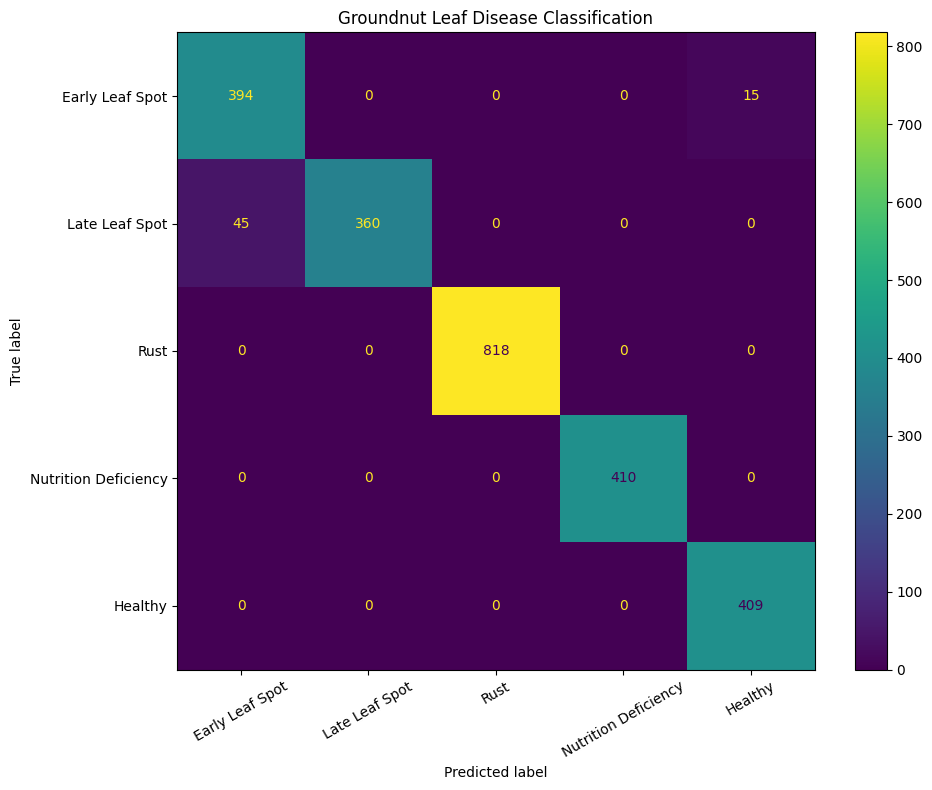

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    xticks_rotation=30
)

plt.title("Groundnut Leaf Disease Classification")
plt.tight_layout()

plt.show()

Load the best trained model
Run this first:$0

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/best_groundnut_model.pth",
        map_location=device
    )
)

model.eval()

print("Best trained model loaded successfully!")

Best trained model loaded successfully!


Select 2 random test images from each class

In [ ]:
import pandas as pd

# Select 2 random samples from each of the 5 classes
sample_df = (
    test_df
    .groupby("class_name", group_keys=False)
    .sample(n=2, random_state=42)
    .reset_index(drop=True)
)

print("Selected test samples:")
print(sample_df[["class_name", "filepath"]])

Selected test samples:
             class_name                                           filepath
0       Early Leaf Spot  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
1       Early Leaf Spot  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
2               Healthy  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
3               Healthy  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
4        Late Leaf Spot  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
5        Late Leaf Spot  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
6  Nutrition Deficiency  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
7  Nutrition Deficiency  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
8                  Rust  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...
9                  Rust  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...


Make predictions$0

In [ ]:
import torch
from PIL import Image

results = []

model.eval()

for _, row in sample_df.iterrows():

    image_path = row["filepath"]
    actual_class = row["class_name"]

    # Open image
    image = Image.open(image_path).convert("RGB")

    # Preprocess
    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():

        output = model(input_tensor)

        probabilities = torch.softmax(output, dim=1)

        confidence, predicted_idx = torch.max(
            probabilities,
            dim=1
        )

    predicted_class = class_names[predicted_idx.item()]
    confidence_score = confidence.item() * 100

    results.append({
        "filepath": image_path,
        "Actual": actual_class,
        "Predicted": predicted_class,
        "Confidence": confidence_score,
        "Correct": actual_class == predicted_class
    })

results_df = pd.DataFrame(results)

print(results_df)

                                            filepath                Actual  \
0  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...       Early Leaf Spot   
1  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...       Early Leaf Spot   
2  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...               Healthy   
3  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...               Healthy   
4  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...        Late Leaf Spot   
5  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...        Late Leaf Spot   
6  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...  Nutrition Deficiency   
7  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...  Nutrition Deficiency   
8  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...                  Rust   
9  /content/Groundnut_Leaf_dataset/Groundnut_Leaf...                  Rust   

              Predicted  Confidence  Correct  
0       Early Leaf Spot   99.987221     True  
1       Early Leaf Spot   99.998248     True  


Display a  results table

In [ ]:
report_table = results_df[
    ["Actual", "Predicted", "Confidence", "Correct"]
].copy()

report_table["Confidence"] = report_table["Confidence"].map(
    lambda x: f"{x:.2f}%"
)

report_table["Correct"] = report_table["Correct"].map(
    {True: "Correct", False: "Incorrect"}
)

report_table.index = range(1, len(report_table) + 1)

print(report_table)

                  Actual             Predicted Confidence    Correct
1        Early Leaf Spot       Early Leaf Spot     99.99%    Correct
2        Early Leaf Spot       Early Leaf Spot    100.00%    Correct
3                Healthy               Healthy     99.98%    Correct
4                Healthy               Healthy    100.00%    Correct
5         Late Leaf Spot        Late Leaf Spot     99.98%    Correct
6         Late Leaf Spot       Early Leaf Spot     94.11%  Incorrect
7   Nutrition Deficiency  Nutrition Deficiency     99.96%    Correct
8   Nutrition Deficiency  Nutrition Deficiency     99.98%    Correct
9                   Rust                  Rust     99.94%    Correct
10                  Rust                  Rust     99.96%    Correct


output for your report

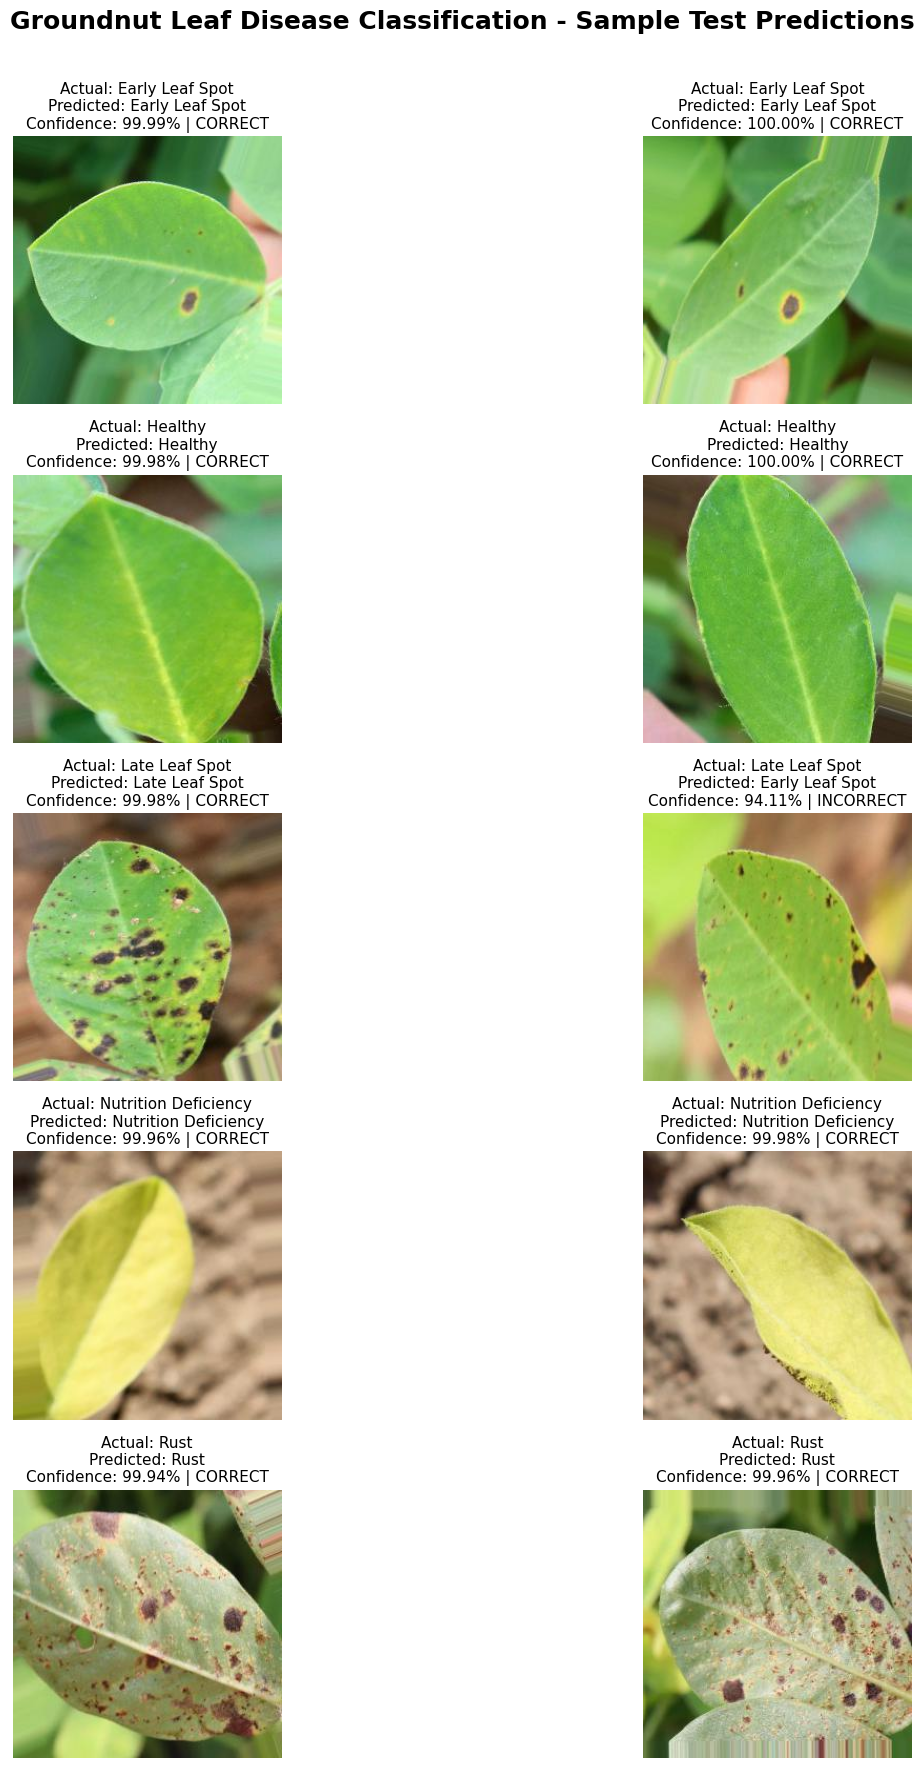

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 18))

for i, row in results_df.iterrows():

    image = Image.open(row["filepath"]).convert("RGB")

    plt.subplot(5, 2, i + 1)

    plt.imshow(image)

    actual = row["Actual"]
    predicted = row["Predicted"]
    confidence = row["Confidence"]

    status = "CORRECT" if row["Correct"] else "INCORRECT"

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.2f}% | {status}",
        fontsize=11
    )

    plt.axis("off")

plt.suptitle(
    "Groundnut Leaf Disease Classification - Sample Test Predictions",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    "/content/sample_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()